# День 08. Упражнение 05
# Кластеризация

## 0. Импорты

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

## 1. Предобработка

1. Прочитай файл [`regression.csv`](https://drive.google.com/file/d/1fzOPkuXoxLleOsvNVCT0m-LKxlid33ma/view?usp=sharing) в DataFrame.
2. Удали колонку `pageviews`, мы будем кластеризовать пользователей только по количеству коммитов и их средней разнице.

In [60]:
df = pd.read_csv("../data/regression.csv")
df = df.drop(columns=["pageviews"]).set_index("uid")
df.head(3)

,num_commits,AVG(diff)
uid,,
user_1,62,-64.4
user_10,20,-74.8
user_14,61,-159.0


## 2. KMeans

1. Ознакомься с документацией и разберись, как работает этот алгоритм.
2. Используй этот алгоритм для создания кластеров с параметрами `random_state=21` и `n_clusters=3`.

In [78]:
model_k3 = KMeans(n_clusters=3, random_state=21)

In [79]:
labels_k3 = model_k3.fit_predict(df)

3. Визуализируй данные на `scatter plot`.

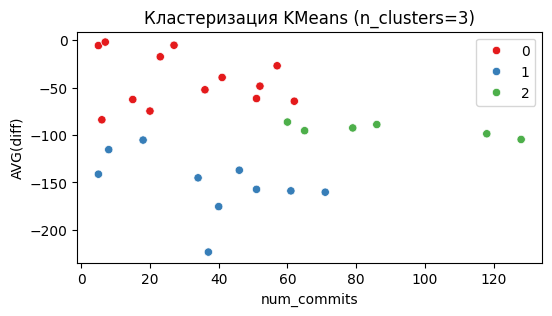

In [81]:
plt.figure(figsize=(6, 3))
sns.scatterplot(data=df, x="num_commits", y="AVG(diff)", hue=labels_k3, palette="Set1")
plt.title("Кластеризация KMeans (n_clusters=3)")
plt.show()

4. Попробуй разные значения `n_clusters` и посмотри, как изменится твой график.
5. Вычисли `silhouette_score` (см. документацию по метрике).

In [88]:
silhouette_k3 = silhouette_score(df, labels_k3)
print(f"silhouette_score для 3 кластеров: {silhouette_k3}")

silhouette_score для 3 кластеров: 0.4454402135233297


помимо визуальной оценки действия изменения кол-ва кластеров на графиках или расчета метрики silhouette_score также прменяют метод (локтя) графичекой оценки графика изменения суммы квадратов расстояний от точек до ближайших центров кластеров (SSD - Sum of squared distances или model.inertia_) от значений n_clusters. Анализируется уменьшение метрики SSD ("точки локтя"): ищется наиболее пологий отрезок, который имеет минимальное изменение ssd при увеличении n_cluster на 1. эти точки говорят о том, что дальнейшее увелиение k (или n_cluster) не извлекает больше "сигнала" из данных. 

In [84]:
ssd = []
silhouettes = []
cluster_range = range(2, 10)

for n_cluster in cluster_range:
    model = KMeans(n_clusters=n_cluster, random_state=21)
    labels = model.fit_predict(df)

    ssd.append(model.inertia_)
    silhouettes.append(silhouette_score(df, labels))

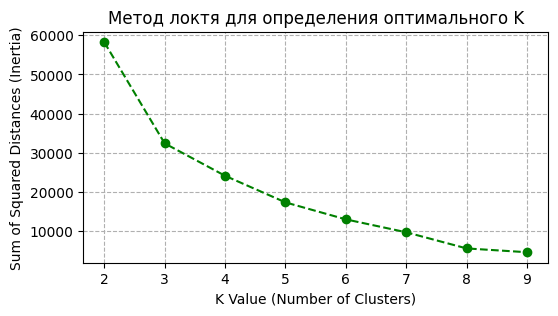

In [96]:
plt.figure(figsize=(6, 3))
plt.plot(cluster_range, ssd, "o--", color="g")
plt.xlabel("K Value (Number of Clusters)")
plt.ylabel("Sum of Squared Distances (Inertia)")
plt.title("Метод локтя для определения оптимального K")
plt.grid(True, linestyle="--")
plt.show()

In [104]:
for n_clusters, silhouette in zip(cluster_range, silhouettes):
    print(f"при K = {n_clusters} | Silhouette Score = {silhouette:.16f}")

при K = 2 | Silhouette Score = 0.4194920562377423
при K = 3 | Silhouette Score = 0.4454402135233297
при K = 4 | Silhouette Score = 0.4150387993626896
при K = 5 | Silhouette Score = 0.3521030626149593
при K = 6 | Silhouette Score = 0.3954350435152892
при K = 7 | Silhouette Score = 0.3963747661984396
при K = 8 | Silhouette Score = 0.4863808732022785
при K = 9 | Silhouette Score = 0.4537667044117413


Подытоживая: если смотреть только на значения `silhouette score` для `KMeans`, то максимальный балл `0.4863` выдает разбиение на `8 кластеров`, но если смотреть на график метода локтя, то точка перелома, после которой график начинает падать монотонно и полого находится в точке K = 3

$$Silhouette\_score = \frac{b - a}{\max(a, b)}$$
значения от -1 до 1, где 
1  - это отличные кластеры
0   - плохие кластеры
<0  - пересечение кластеров

## 3. DBSCAN

1. Ознакомься с документацией и разберись, как работает этот алгоритм.
2. Используй этот алгоритм для создания кластеров с параметрами `eps=20` и `min_samples=2`.

In [106]:
model_dbs = DBSCAN(eps=20, min_samples=2)
labels_dbs = model_dbs.fit_predict(df)

3. Визуализируй данные на `scatter plot`

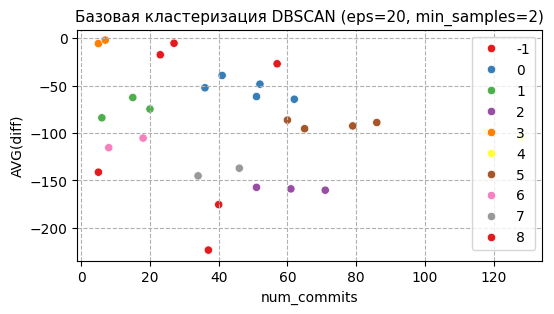

In [117]:
plt.figure(figsize=(6, 3))
sns.scatterplot(data=df, x="num_commits", y="AVG(diff)", hue=labels_dbs, palette="Set1")
plt.title("Базовая кластеризация DBSCAN (eps=20, min_samples=2)", fontsize=11)
plt.grid(True, linestyle="--")
plt.show()

In [111]:
print(f"Silhouette Score для DBSCAN: {silhouette_score(df, labels_dbs)}")

Silhouette Score для DBSCAN: 0.38339641455696616


4. Попробуй разные значения `eps` и `min_samples` и посмотри, как изменится твой график.
5. Вычисли `silhouette_score` (см. документацию по метрике).

In [145]:
dbs_grid_results = []

for eps in range(10, 40):
    for min_samples in range(1, 10):
        dbs_test = DBSCAN(eps=eps, min_samples=min_samples)
        test_labels = dbs_test.fit_predict(df)

        unique_labels = np.unique(test_labels)

        # если все точки шум (-1), тогда силуэт не посчитать
        num_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

        if (
            num_clusters > 1
        ):  # метрика силуэта измеряет качество разделения на группы => т.е их должно быть минимум две.
            score = silhouette_score(df, test_labels)

            dbs_grid_results.append(
                {
                    "eps": eps,
                    "min_samples": min_samples,
                    "silhouette_score": score,
                    "num_clusters": num_clusters,
                }
            )

In [146]:
# dbs_grid_results

In [148]:
df_dbs_grid = pd.DataFrame(dbs_grid_results)
df_dbs_grid.sort_values(by="silhouette_score", ascending=False).head(1)

,eps,min_samples,silhouette_score,num_clusters
35,22,1,0.48713,9


## 4. Иерархическая кластеризация (AgglomerativeClustering)

1. Используй этот алгоритм для создания кластеров с параметром `n_clusters=5`.
2. Визуализируй данные на `scatter plot`.
3. Попробуй разные значения `n_clusters` и посмотри, как изменится твой график.
4. Вычисли `silhouette_score`.
5. Визуализируй `dendrogram`.

Функция для рисования иерархического дерева dendrogram для данного алгоритма находится не в sklearn, а в библиотеке scipy.cluster.hierarchy. Чтобы она сработала, ей на вход нужно передать не сам объект модели, а специальную матрицу связей, посчитанную через функцию linkage

In [151]:
model_aggl = AgglomerativeClustering(n_clusters=5)
cluster_labels = model_aggl.fit_predict(df)

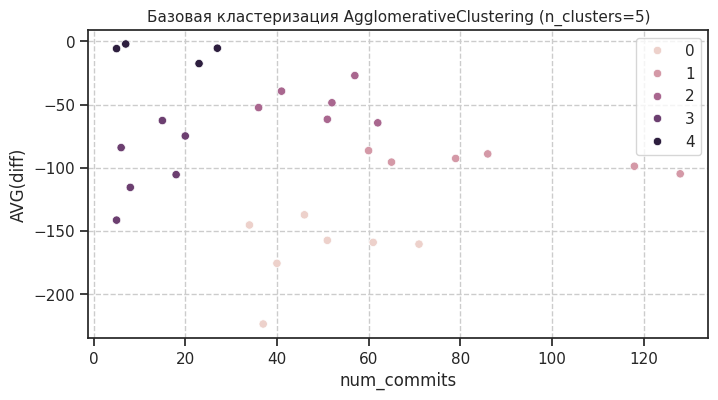

In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="num_commits", y="AVG(diff)", hue=cluster_labels)
plt.title("Базовая кластеризация AgglomerativeClustering (n_clusters=5)", fontsize=11)
plt.grid(True, linestyle="--")
plt.show()

In [166]:
for k in range(2, 10):
    model_agg_test = AgglomerativeClustering(n_clusters=k)
    test_labels_agg = model_agg_test.fit_predict(df)

    score_k = silhouette_score(df, test_labels_agg)
    print(f"n_clusters = {k:<2} │ silhouette_score = {score_k:.16f}")

n_clusters = 2  │ silhouette_score = 0.3590249057222198
n_clusters = 3  │ silhouette_score = 0.3390493703444805
n_clusters = 4  │ silhouette_score = 0.4448362750283643
n_clusters = 5  │ silhouette_score = 0.4638301519938147
n_clusters = 6  │ silhouette_score = 0.4527145606287827
n_clusters = 7  │ silhouette_score = 0.4865808853184314
n_clusters = 8  │ silhouette_score = 0.5077985556562200
n_clusters = 9  │ silhouette_score = 0.4757686903914756


`AgglomerativeClustering`: По результатам расчета оптимальное количество кластеров = `8`, так как имеем максимальный silhouette_score = `0.5077985556562200`

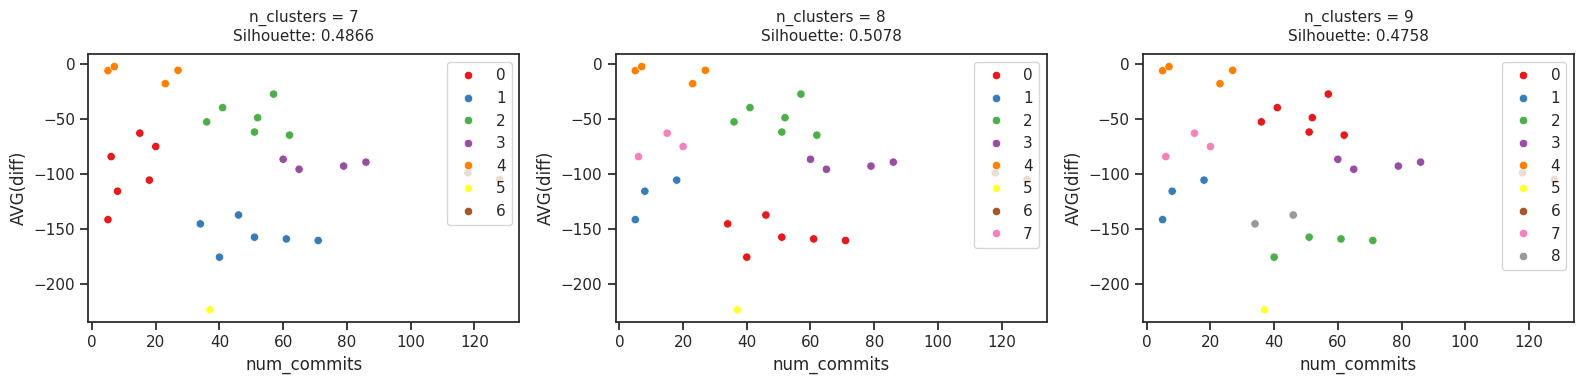

In [180]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, k in zip(axes, range(7, 10)):
    model_test = AgglomerativeClustering(n_clusters=k)
    test_labels = model_test.fit_predict(df)
    score_k = silhouette_score(df, test_labels)

    sns.scatterplot(
        data=df,
        x="num_commits",
        y="AVG(diff)",
        hue=test_labels,
        palette="Set1",
        ax=ax,
    )
    ax.set_title(f"n_clusters = {k}\nSilhouette: {score_k:.4f}", fontsize=11, pad=10)
    ax.legend(title="", loc="upper right")

plt.tight_layout()
plt.show()


## 5. Функция

Напиши функцию, которая:
1. Принимает аргументы: класс модели кластеризации, её параметры, имя параметра для оптимизации и диапазон значений этого параметра.
2. Перебирает разные значения из заданного диапазона и вычисляет `silhouette_score` для каждого значения.
3. Определяет лучшее значение параметра в диапазоне.
4. Возвращает два подграфика:

- первый показывает, как `silhouette_score` меняется в зависимости от значения параметра;
- второй визуализирует данные на `scatter plot` с использованием модели кластеризации с лучшим найденным значением параметра.

In [ ]:
def calc_parameters():